1.การเตรียมข้อมูล

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns  # แก้ไขจาก sns as sns เป็น seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
import os
import kagglehub

# 1. ดาวน์โหลดข้อมูล CR7
path = kagglehub.dataset_download("azminetoushikwasi/cr7-cristiano-ronaldo-all-club-goals-stats")

# 2. โหลดไฟล์ (ใช้ชื่อไฟล์ที่ถูกต้องใน Dataset)
file_path = os.path.join(path, "data.csv")
df = pd.read_csv(file_path)

# 3. เตรียม Features
# จัดการเรื่องนาที (Minute) ให้เป็นตัวเลขล้วน
df['Minute_Clean'] = df['Minute'].apply(lambda x: sum(int(i) for i in str(x).split('+')) if '+' in str(x) else int(x) if str(x).isdigit() else 0)

# แปลงข้อมูลตัวหนังสือเป็นตัวเลข
le = LabelEncoder()
df['Type_Code'] = le.fit_transform(df['Type'].fillna('Unknown'))
df['Venue_Code'] = le.fit_transform(df['Venue'].fillna('Unknown'))

features = ['Minute_Clean', 'Type_Code', 'Venue_Code']
data_numeric = df[features]

# 4. Scaling
scaler = StandardScaler()
scaled_data = scaler.fit_transform(data_numeric)

print(f"เตรียมข้อมูล CR7 สำเร็จ! รวมทั้งหมด {len(df)} ประตู")

100%|██████████| 12.2k/12.2k [00:00<00:00, 14.7MB/s]

Extracting files...
เตรียมข้อมูล CR7 สำเร็จ! รวมทั้งหมด 710 ประตู


2.การฝึกแบบจำลอง

In [6]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# 1. Clustering
kmeans = KMeans(n_clusters=3, random_state=42, n_init='auto')
df['Cluster'] = kmeans.fit_predict(scaled_data)

# 2. PCA
pca = PCA(n_components=2)
pca_result = pca.fit_transform(scaled_data)
df['PC1'] = pca_result[:, 0]
df['PC2'] = pca_result[:, 1]

print("ฝึกโมเดลจัดกลุ่มและลดมิติเรียบร้อย")

ฝึกโมเดลจัดกลุ่มและลดมิติเรียบร้อย


C:\Users\USER\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(


3.การวัดผลและการนำเสนอ

C:\Users\USER\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
C:\Users\USER\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
C:\Users\USER\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
C:\Users\USER\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows wi

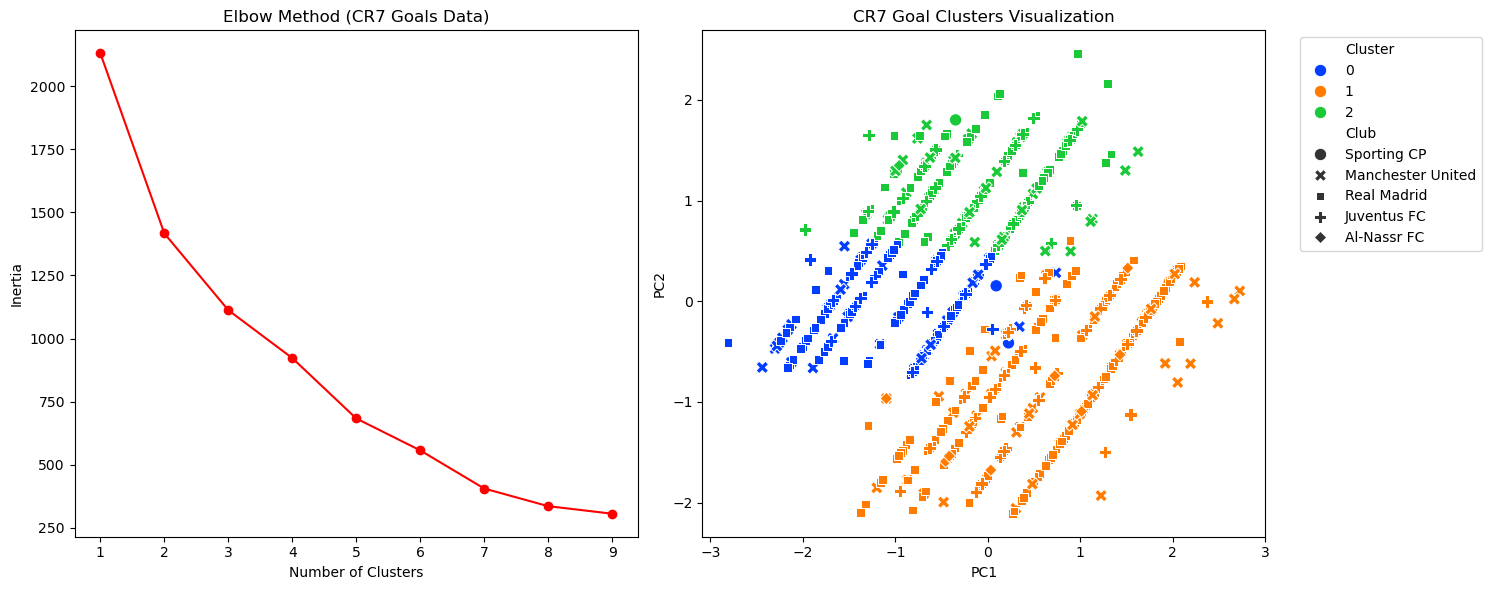

--- บทสรุปจากข้อมูล ---
Cluster 0: พบทั้งหมด 187 ประตู | ช่วงนาทีเฉลี่ยที่ยิงคือ 25.22
Cluster 1: พบทั้งหมด 306 ประตู | ช่วงนาทีเฉลี่ยที่ยิงคือ 51.40
Cluster 2: พบทั้งหมด 217 ประตู | ช่วงนาทีเฉลี่ยที่ยิงคือ 71.59


In [7]:
plt.figure(figsize=(15, 6))

# 1. Elbow Method เพื่อวัดผลความเหมาะสมของ K
distortions = []
K = range(1, 10)
for k in K:
    km = KMeans(n_clusters=k, n_init='auto', random_state=42)
    km.fit(scaled_data)
    distortions.append(km.inertia_)

plt.subplot(1, 2, 1)
plt.plot(K, distortions, 'ro-')
plt.title('Elbow Method (CR7 Goals Data)')
plt.xlabel('Number of Clusters')
plt.ylabel('Inertia')

# 2. PCA Scatter Plot นำเสนอข้อมูล
plt.subplot(1, 2, 2)
# ใช้ Cluster เป็นสี และใช้ Club (สโมสร) เป็นรูปร่างของจุด
sns.scatterplot(x='PC1', y='PC2', hue='Cluster', style='Club', data=df, palette='bright', s=80)
plt.title('CR7 Goal Clusters Visualization')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

# สรุปผลการประยุกต์ใช้
print("--- บทสรุปจากข้อมูล ---")
cluster_stats = df.groupby('Cluster')['Minute_Clean'].mean()
for i, val in cluster_stats.items():
    count = len(df[df['Cluster'] == i])
    print(f"Cluster {i}: พบทั้งหมด {count} ประตู | ช่วงนาทีเฉลี่ยที่ยิงคือ {val:.2f}")